<a href="https://colab.research.google.com/github/mmjtech20-pixel/MLT-Practicals/blob/main/Softmax.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.utils import to_categorical
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

In [ ]:
iris = load_iris()
X = iris.data
y = iris.target

y_encoded = to_categorical(y)

X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.2, random_state=42)

In [ ]:
model = Sequential([
    Dense(8, input_shape=(4,), activation='relu'),
    Dense(3, activation='softmax')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

In [ ]:
history = model.fit(X_train, y_train, epochs=100, batch_size=8, validation_split=0.2, verbose=0)

In [ ]:
sample = np.array([[5.1, 3.5, 1.4, 0.2]])
prediction = model.predict(sample)
predicted_class = np.argmax(prediction)

print("\nPredicted Probabilities (Softmax Output):", prediction)
print("Predicted Class:", iris.target_names[predicted_class])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step

Predicted Probabilities (Softmax Output): [[0.5851565  0.24658708 0.1682564 ]]
Predicted Class: setosa


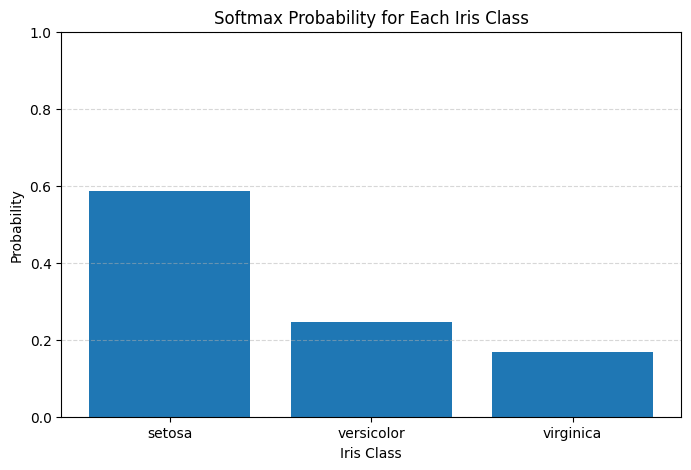

In [ ]:
# Extract probabilities
probabilities = prediction[0]
classes = iris.target_names

# Plot
plt.figure(figsize=(8, 5))
plt.bar(classes, probabilities)

plt.title('Softmax Probability for Each Iris Class')
plt.xlabel('Iris Class')
plt.ylabel('Probability')
plt.ylim(0, 1)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()

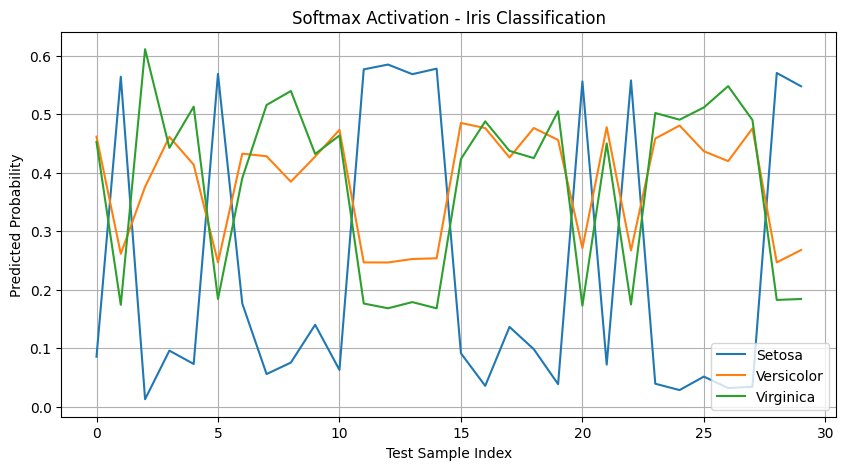

In [ ]:
# Get predicted probabilities for all test samples
y_prob = model.predict(X_test, verbose=0)

# Plot Softmax output
plt.figure(figsize=(10, 5))

plt.plot(y_prob[:, 0], label='Setosa')
plt.plot(y_prob[:, 1], label='Versicolor')
plt.plot(y_prob[:, 2], label='Virginica')

plt.title('Softmax Activation - Iris Classification')
plt.xlabel('Test Sample Index')
plt.ylabel('Predicted Probability')
plt.legend()
plt.grid(True)

plt.show()